# 색상 히스토그램, 히스토그램 정규화, 히스토그램 평활화

### bgr -> hsv (색상, 명도, 밝기)
### 히스토그램 구하기
### matplotlib를 이용해서 히스토그램 그림

In [1]:
# 공통부분이기 때문에 실습을 새로운 notebook에서 할때마다 복사해서 실행
import sys
sys.path.append('../multi_info/common') # 모듈이 존재하는 path를 추가
import cvnb
import cv2
import numpy as np
import matplotlib.pyplot as plt

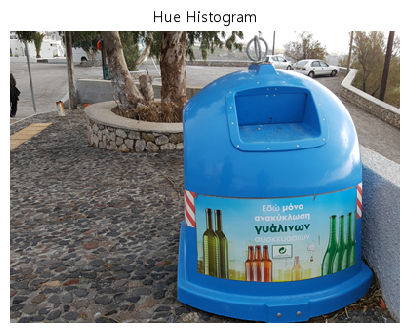

In [2]:
image = cv2.imread("../multi_info/images/hue_hist.jpg", cv2.IMREAD_COLOR)
if image is None: raise Exception("영상 파일 읽기 오류")
cv2.imshow("Hue Histogram", image)

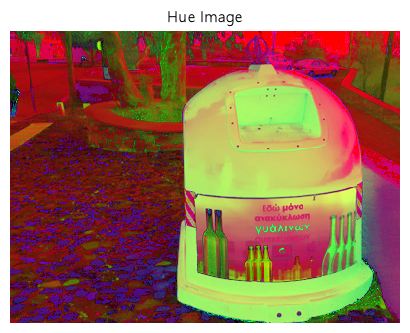

In [3]:
hsv_img = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
cv2.imshow("Hue Image", hsv_img)

In [6]:
hue_hist = cv2.calcHist([hsv_img], [0], None, [18], [0, 180])
print(hue_hist[:20])

[11527. 32780. 10939.  5821.   822.   722.   292.  2427.  1439.  7224.
 35324.  3625.  2839.   252.   729.   207.  1820.  1211.]


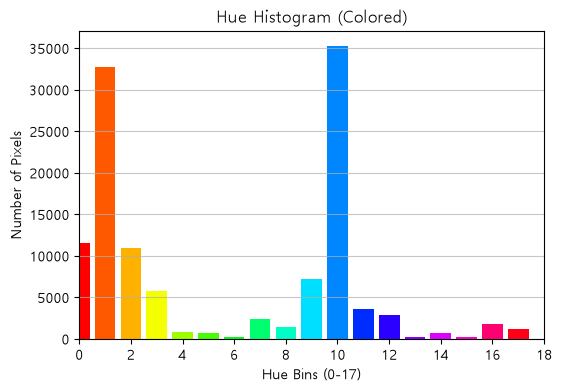

In [7]:
# matplotlib를 이용해서 히스토그램 표시
cmap = plt.get_cmap('hsv')
colors = cmap(np.linspace(0, 1, 18))
plt.figure(figsize=(6,4))
plt.title("Hue Histogram (Colored)")
plt.xlabel("Hue Bins (0-17)")
plt.ylabel("Number of Pixels")
plt.bar(np.arange(18), hue_hist.flatten(), color=colors, width=0.8)
plt.xlim([0, 18])
plt.grid(axis='y', alpha=0.7)
plt.show()

In [9]:
# 자주 사용하는 히스토그램 그리는 함수 생성
def draw_hist(title, nbins, hist):
    plt.figure(figsize=(6,4))
    plt.title(title)
    plt.xlabel(f"Bins (0-{nbins})")
    plt.ylabel("Number of Pixels")
    plt.bar(np.arange(nbins), hist.flatten(), color='black', width=0.95)
    plt.xlim([0, nbins])
    plt.grid(axis='y', alpha=0.7)
    plt.show()

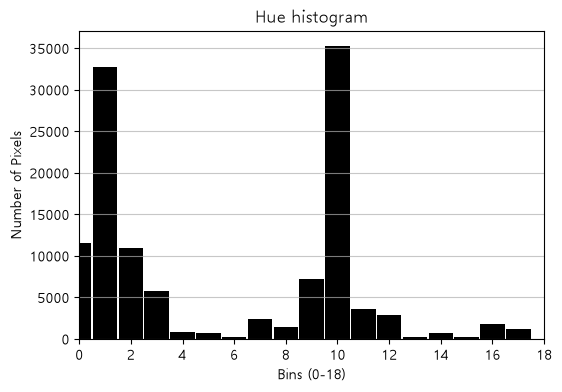

In [10]:
draw_hist("Hue histogram", 18, hue_hist) # 테스트 복적

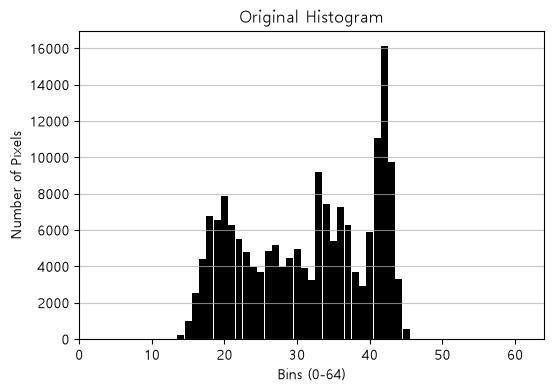

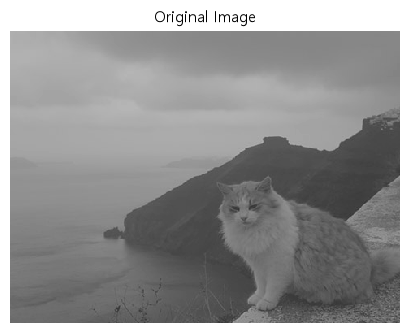

In [11]:
str_image = cv2.imread("../multi_info/images/hist_stretch.jpg", cv2.IMREAD_GRAYSCALE)
if str_image is None: raise Exception("영상 파일 읽기 오류")
cv2.imshow("Original Image", str_image)
str_hist = cv2.calcHist([str_image], [0], None, [64], [0,256])
draw_hist("Original Histogram", 64, str_hist)

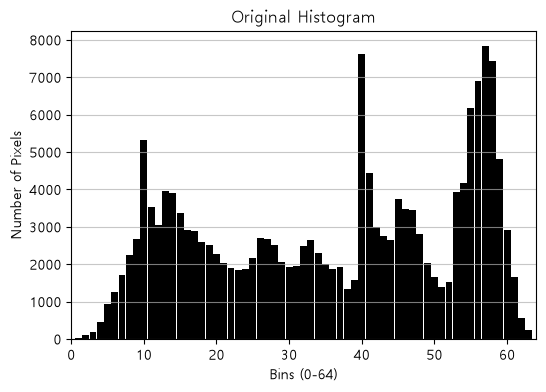

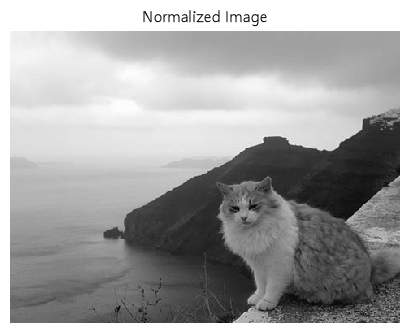

In [12]:
norm_image = cv2.normalize(str_image, None, 0, 255, cv2.NORM_MINMAX)
cv2.imshow("Normalized Image", norm_image)
norm_hist = cv2.calcHist([norm_image], [0], None, [64], [0,256])
draw_hist("Original Histogram", 64, norm_hist)

In [13]:
equ_image = cv2.equalizeHist(str_image) # opencv를 이용한 평활화

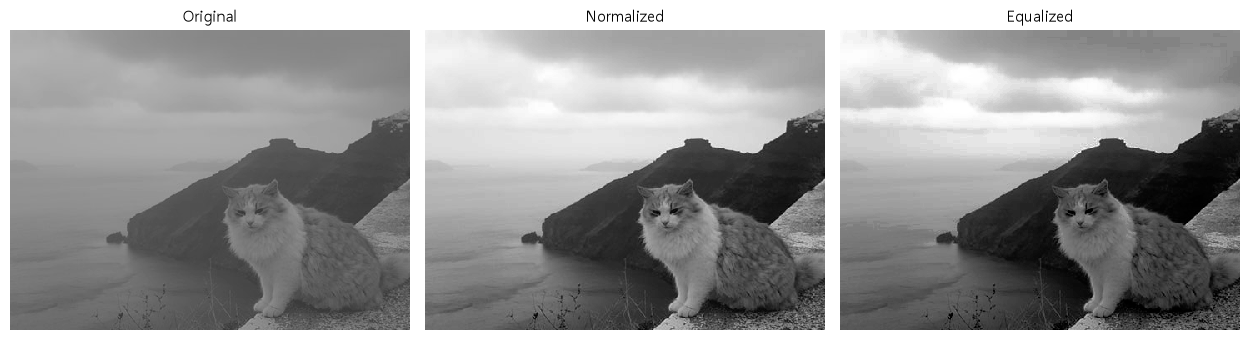

In [14]:
cv2.imshow("Original", str_image)
cv2.imshow("Normalized", norm_image)
cv2.imshow("Equalized", equ_image)

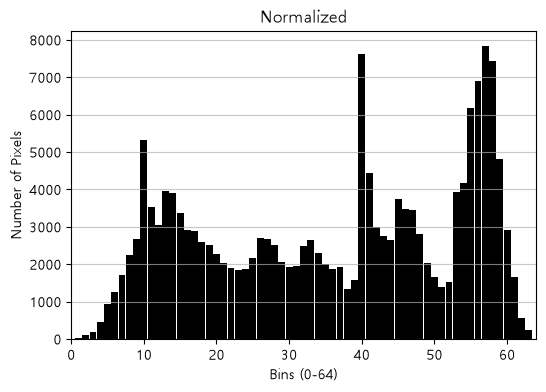

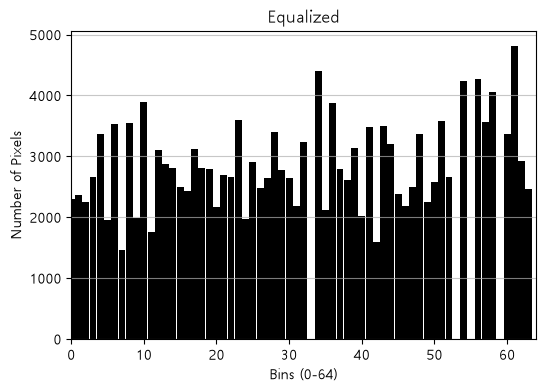

In [15]:
equ_hist = cv2.calcHist([equ_image], [0], None, [64], [0,256])

draw_hist("Normalized", 64, norm_hist)
draw_hist("Equalized", 64, equ_hist)

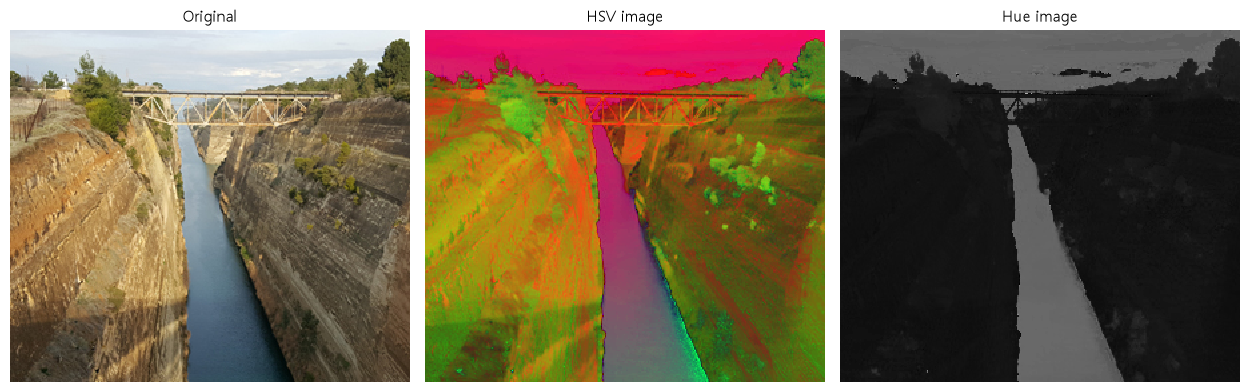

In [16]:
BGR_img = cv2.imread("../multi_info/images/color_space.jpg", cv2.IMREAD_COLOR)
if BGR_img is None: raise Exception("영상 파일 읽기 오류")
HSV_img = cv2.cvtColor(BGR_img, cv2.COLOR_BGR2HSV)
hue, _, _ = cv2.split(HSV_img)

cv2.imshow("Original", BGR_img)
cv2.imshow("HSV image", HSV_img)
cv2.imshow("Hue image", hue)

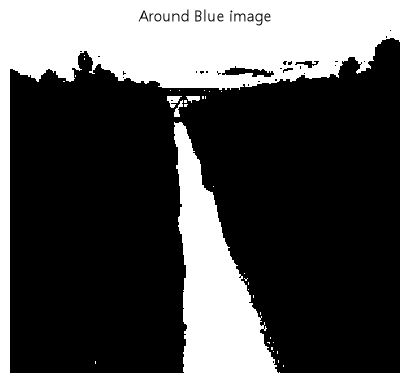

In [19]:
_, result = cv2.threshold(hue, 150, 255, cv2.THRESH_TOZERO_INV)
_, result = cv2.threshold(result, 90, 255, cv2.THRESH_BINARY)
cv2.imshow("Around Blue image", result)